##### Cell 1: Load Data and Prepare the Target

In [1]:

# ==========================================================
# IT3091 - Telco Customer Churn
# Stage 4: Exploratory Data Analysis
# Responsibility: IT24102178 - EDA
# ==========================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

dataset_path = (
    project_root / "data" / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(dataset_path)

# Repeat the documented, deterministic cleaning rule
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

zero_tenure_mask = (
    df["tenure"].eq(0)
    & df["TotalCharges"].isna()
)

df.loc[zero_tenure_mask, "TotalCharges"] = 0.0

assert df["TotalCharges"].isna().sum() == 0

# Numeric target for analysis only
df["ChurnBinary"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Dataset shape:", df.shape)
print("Overall churn rate:", round(df["ChurnBinary"].mean() * 100, 2), "%")


Dataset shape: (7043, 22)
Overall churn rate: 26.54 %


##### Cell 2 — Churn by contract type

,Customers,Churned,ChurnRate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


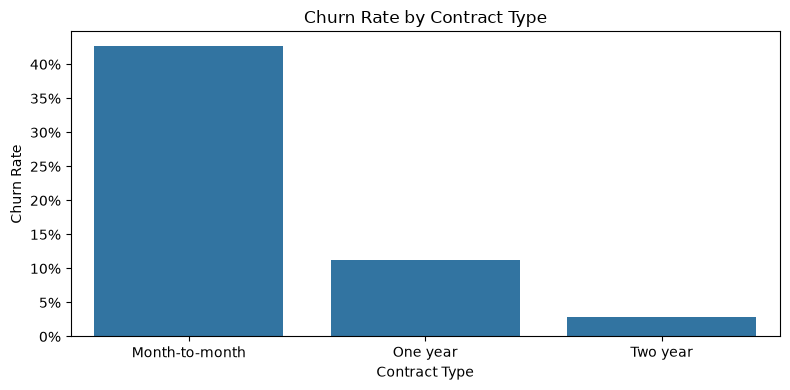

In [2]:

# Responsibility: IT24102178 - EDA

contract_summary = (
    df.groupby("Contract")["ChurnBinary"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Customers",
        "sum": "Churned",
        "mean": "ChurnRate"
    })
)

contract_summary["ChurnRate"] *= 100
contract_summary = contract_summary.round(2)

display(contract_summary)

plt.figure(figsize=(8, 4))
sns.barplot(
    data=df,
    x="Contract",
    y="ChurnBinary",
    estimator=np.mean,
    errorbar=None
)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x * 100:.0f}%")
)
plt.tight_layout()
plt.show()


##### Cell 3 — Churn by tenure group

,Customers,ChurnRate
TenureGroup,,
0-12 months,2186,47.44
13-24 months,1024,28.71
25-48 months,1594,20.39
49-72 months,2239,9.51


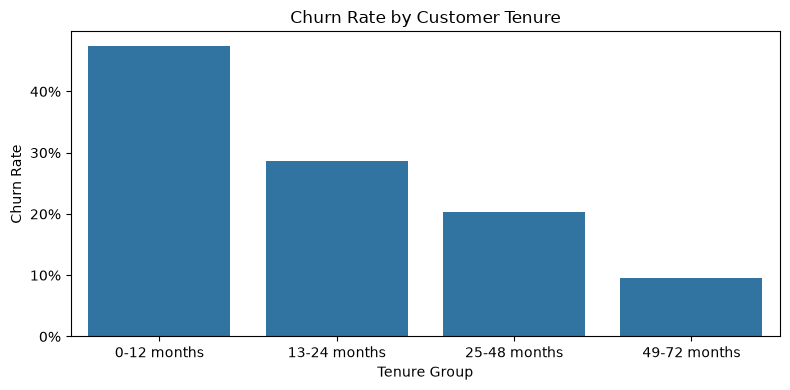

In [3]:

# Responsibility: IT24102178 - EDA

tenure_bins = [-1, 12, 24, 48, 72]
tenure_labels = [
    "0-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels
)

tenure_summary = (
    df.groupby("TenureGroup", observed=True)["ChurnBinary"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Customers",
        "mean": "ChurnRate"
    })
)

tenure_summary["ChurnRate"] *= 100
display(tenure_summary.round(2))

plt.figure(figsize=(8, 4))
sns.barplot(
    data=df,
    x="TenureGroup",
    y="ChurnBinary",
    estimator=np.mean,
    errorbar=None,
    order=tenure_labels
)
plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x * 100:.0f}%")
)
plt.tight_layout()
plt.show()


##### Cell 4 — Churn by internet service

,Customers,ChurnRate
InternetService,,
DSL,2421,18.96
Fiber optic,3096,41.89
No,1526,7.40


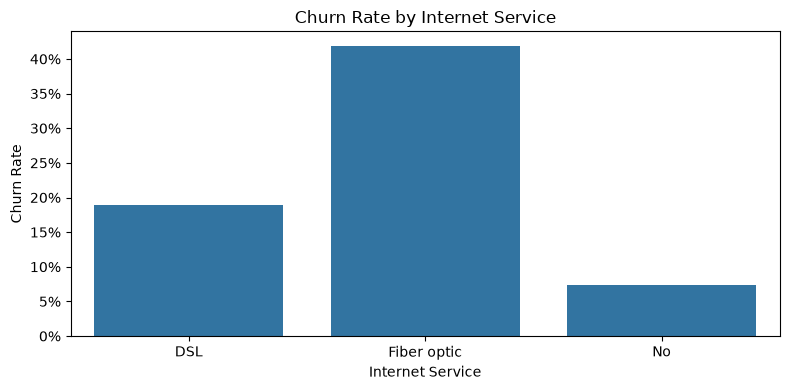

In [4]:

# Responsibility: IT24102178 - EDA

internet_summary = (
    df.groupby("InternetService")["ChurnBinary"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Customers",
        "mean": "ChurnRate"
    })
)

internet_summary["ChurnRate"] *= 100
display(internet_summary.round(2))

plt.figure(figsize=(8, 4))
sns.barplot(
    data=df,
    x="InternetService",
    y="ChurnBinary",
    estimator=np.mean,
    errorbar=None
)
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x * 100:.0f}%")
)
plt.tight_layout()
plt.show()


##### Cell 5 — Churn by payment method

,Customers,ChurnRate
PaymentMethod,,
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24
Electronic check,2365,45.29
Mailed check,1612,19.11


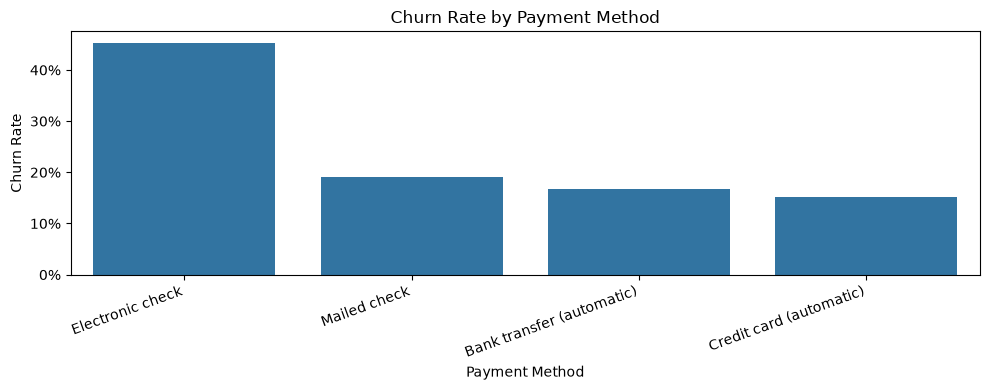

In [5]:

# Responsibility: IT24102178 - EDA

payment_summary = (
    df.groupby("PaymentMethod")["ChurnBinary"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "Customers",
        "mean": "ChurnRate"
    })
)

payment_summary["ChurnRate"] *= 100
display(payment_summary.round(2))

plt.figure(figsize=(10, 4))
sns.barplot(
    data=df,
    x="PaymentMethod",
    y="ChurnBinary",
    estimator=np.mean,
    errorbar=None
)
plt.xticks(rotation=20, ha="right")
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x * 100:.0f}%")
)
plt.tight_layout()
plt.show()


##### Cell 6 — Monthly charges by churn status

,count,mean,median,std
Churn,,,,
No,5174,61.27,64.43,31.09
Yes,1869,74.44,79.65,24.67


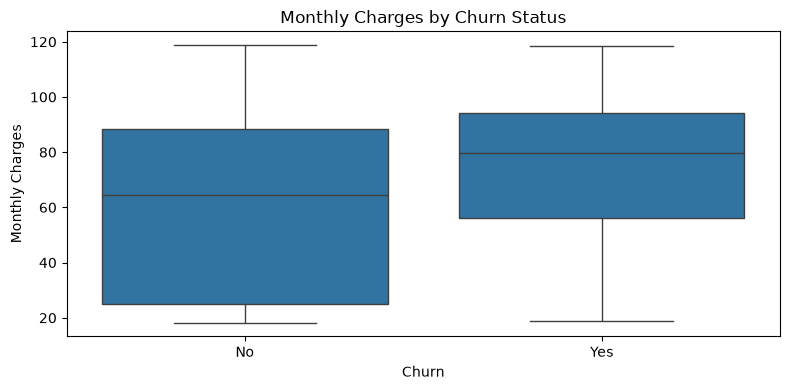

In [6]:

# Responsibility: IT24102178 - EDA

charges_summary = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(charges_summary)

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()


##### Cell 7 — Churn by technical support and online security

In [7]:

# Responsibility: IT24102178 - EDA

for feature in ["TechSupport", "OnlineSecurity"]:
    summary = (
        df.groupby(feature)["ChurnBinary"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Customers",
            "mean": "ChurnRate"
        })
    )

    summary["ChurnRate"] *= 100

    print(f"\nChurn by {feature}")
    display(summary.round(2))



Churn by TechSupport


,Customers,ChurnRate
TechSupport,,
No,3473,41.64
No internet service,1526,7.40
Yes,2044,15.17



Churn by OnlineSecurity


,Customers,ChurnRate
OnlineSecurity,,
No,3498,41.77
No internet service,1526,7.40
Yes,2019,14.61


##### Cell 8 — Correlation between numerical features

,tenure,MonthlyCharges,TotalCharges,ChurnBinary
tenure,1.000,0.248,0.826,-0.352
MonthlyCharges,0.248,1.000,0.651,0.193
TotalCharges,0.826,0.651,1.000,-0.198
ChurnBinary,-0.352,0.193,-0.198,1.000


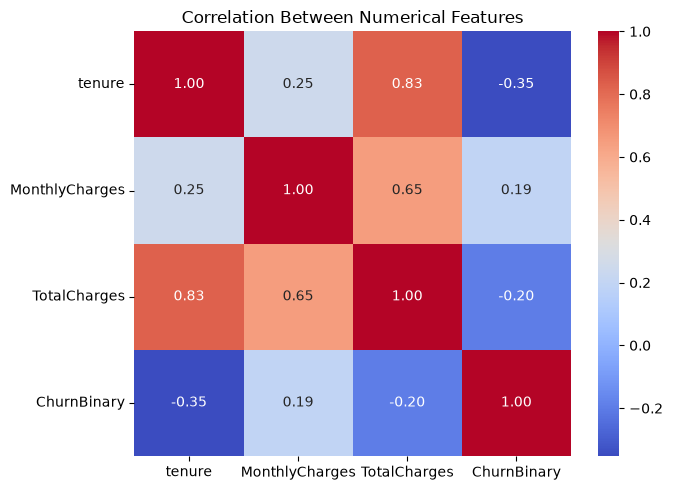

In [8]:

# Responsibility: IT24102178 - EDA

numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ChurnBinary"
]

correlation_matrix = df[numeric_features].corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


##### Cell 9 — Check numerical distributions and potential outliers

,Feature,Lower Bound,Upper Bound,Potential Outliers
0,tenure,-60.00,124.00,0
1,MonthlyCharges,-46.02,171.38,0
2,TotalCharges,-4683.52,8868.67,0


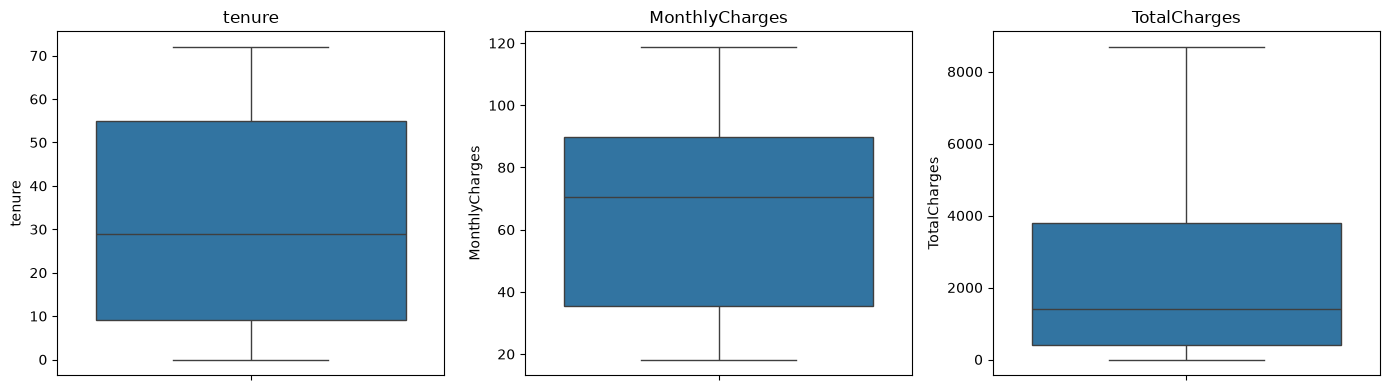

In [9]:

# Responsibility: IT24102310 - Data Quality Assessment
# EDA support: IT24102178

numeric_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

outlier_summary = []

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound)
        | (df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Potential Outliers": int(outlier_count)
    })

display(pd.DataFrame(outlier_summary))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, numeric_columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


##### Cell 10 — Save EDA tables and figures

In [10]:

# Responsibility: IT24102178 - EDA
# Save EDA evidence for final report

output_dir = project_root / "results" / "tables"
output_dir.mkdir(parents=True, exist_ok=True)

contract_summary.to_csv(output_dir / "eda_contract_churn.csv")
tenure_summary.to_csv(output_dir / "eda_tenure_churn.csv")
internet_summary.to_csv(output_dir / "eda_internet_churn.csv")
payment_summary.to_csv(output_dir / "eda_payment_churn.csv")
charges_summary.to_csv(output_dir / "eda_monthly_charges.csv")

print("EDA summary tables saved successfully.")


EDA summary tables saved successfully.
